# 01 — Data profile (SAML-D)

What is in the data, which laundering typologies and look-alike normal behaviours exist, and are there data issues that a rule review has to take into account?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "db.py").exists())
sys.path.insert(0, str(ROOT))

from src.db import connect

pd.set_option("display.max_rows", 60)
con = connect()
q = lambda view: con.sql(f"SELECT * FROM {view}").df()

## 1. Overview

In [2]:
display(q("prof_overview").T)
q("prof_laundering_accounts")

,0
transactions,9504852
first_date,2022-10-07 00:00:00
last_date,2023-08-23 00:00:00
sending_accounts,292715
receiving_accounts,652266
laundering_transactions,9873.0
laundering_pct,0.1039
total_amount_bn,83.291


,side,accounts
0,sender,4950
1,receiver,4074
2,either,7902


## 2. Typologies
Laundering typologies (`is_laundering = 1`) and the normal behaviours that resemble them (`Normal_*`). The look-alikes are the main source of false alerts.

In [3]:
q("prof_typology")

,is_laundering,typology,transactions,sending_accounts,median_amount,mean_amount
0,1,Structuring,1870,1870,4800.35,5245.80
1,1,Cash_Withdrawal,1334,88,139.13,154.32
2,1,Deposit-Send,945,563,6331.86,9180.84
3,1,Smurfing,932,63,2629.43,2802.94
4,1,Layered_Fan_In,656,491,10726.06,17686.85
5,1,Layered_Fan_Out,529,215,6729.77,8628.65
6,1,Stacked Bipartite,506,187,7882.62,9726.53
7,1,Behavioural_Change_1,394,53,3117.91,4878.51
8,1,Bipartite,383,74,8900.82,11790.67
9,1,Cycle,382,382,21494.89,28025.67


## 3. Payment types, locations and amounts

In [4]:
q("prof_payment_type")

,payment_type,transactions,laundering_transactions,laundering_pct,median_amount
0,Credit card,2012909,1136.0,0.0564,6354.61
1,Debit card,2012103,1124.0,0.0559,6352.35
2,Cheque,2011419,1087.0,0.0540,6350.21
3,ACH,2008807,1159.0,0.0577,6360.19
4,Cross-border,933931,2628.0,0.2814,7453.03
5,Cash Withdrawal,300477,1334.0,0.4440,139.27
6,Cash Deposit,225206,1405.0,0.6239,1766.90


In [5]:
q("prof_receiver_location")

,receiver_location,transactions,laundering_transactions,laundering_pct
0,UK,8864634,7308.0,0.0824
1,Pakistan,38980,169.0,0.4336
2,Austria,38844,154.0,0.3965
3,Albania,38783,235.0,0.6059
4,Japan,38729,83.0,0.2143
5,Morocco,38704,253.0,0.6537
6,Germany,38540,102.0,0.2647
7,France,38512,82.0,0.2129
8,Mexico,38385,197.0,0.5132
9,Nigeria,38272,251.0,0.6558


In [6]:
q("prof_amount_quantiles")

,is_laundering,p01,p25,p50,p75,p99,max
0,0,69.10,2142.93,6114.63,10458.95,44938.16,999962.19
1,1,47.99,2723.79,5322.79,9789.67,419540.08,12618498.40


Which payment types does each laundering typology use? This tells us which rule can catch which typology.

In [7]:
con.sql("""
    PIVOT (SELECT typology, payment_type FROM tx WHERE is_laundering = 1)
    ON payment_type USING COUNT(*) GROUP BY typology ORDER BY typology
""").df().set_index("typology").fillna(0).astype(int)

,ACH,Cash Deposit,Cash Withdrawal,Cheque,Credit card,Cross-border,Debit card
typology,,,,,,,
Behavioural_Change_1,42,0,0,42,29,258,23
Behavioural_Change_2,0,0,0,0,0,345,0
Bipartite,76,0,0,71,72,92,72
Cash_Withdrawal,0,0,1334,0,0,0,0
Cycle,63,0,0,51,62,159,47
Deposit-Send,25,473,0,36,35,338,38
Fan_In,79,0,0,72,85,46,82
Fan_Out,38,0,0,40,37,89,33
Gather-Scatter,76,0,0,62,73,50,93


## 4. Volume over time

,month,transactions,laundering_transactions,laundering_pct
0,2022-10-01,708654,694.0,0.0979
1,2022-11-01,897621,794.0,0.0885
2,2022-12-01,900341,907.0,0.1007
3,2023-01-01,908320,940.0,0.1035
4,2023-02-01,904806,946.0,0.1046
5,2023-03-01,908562,927.0,0.1020
6,2023-04-01,902883,962.0,0.1065
7,2023-05-01,917601,866.0,0.0944
8,2023-06-01,897243,1024.0,0.1141
9,2023-07-01,902239,983.0,0.1090


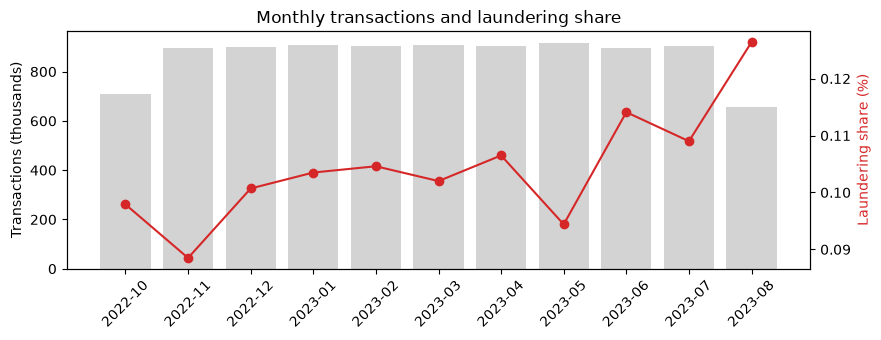

In [8]:
monthly = q("prof_monthly")
fig, ax1 = plt.subplots(figsize=(9, 3.5))
ax1.bar(monthly["month"].dt.strftime("%Y-%m"), monthly["transactions"] / 1e3, color="lightgrey")
ax1.set_ylabel("Transactions (thousands)")
ax2 = ax1.twinx()
ax2.plot(monthly["month"].dt.strftime("%Y-%m"), monthly["laundering_pct"], "o-", color="tab:red")
ax2.set_ylabel("Laundering share (%)", color="tab:red")
ax1.set_title("Monthly transactions and laundering share")
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "docs" / "figures" / "01_monthly_volume.png", dpi=150)
monthly

## 5. Data quality

In [9]:
display(q("dq_checks").T)
display(q("dq_duplicates"))
con.sql("""
    SELECT payment_type, sender_location, receiver_location, payment_currency, received_currency, COUNT(*) AS n
    FROM tx
    WHERE (payment_type <> 'Cross-border' AND sender_location <> receiver_location)
       OR (payment_currency <> received_currency AND sender_location = receiver_location)
    GROUP BY ALL ORDER BY n DESC LIMIT 10
""").df()

,0
rows_with_nulls,0.0
non_positive_amounts,0.0
self_transfers,0.0
cross_border_same_location,0.0
domestic_type_different_location,417.0
currency_change_same_location,155692.0


,duplicated_rows
0,0


,payment_type,sender_location,receiver_location,payment_currency,received_currency,n
0,Cheque,UK,UK,UK pounds,Moroccan dirham,1688
1,Credit card,UK,UK,UK pounds,Turkish lira,1643
2,Credit card,UK,UK,UK pounds,Yen,1635
3,ACH,UK,UK,UK pounds,Yen,1635
4,Debit card,UK,UK,UK pounds,US dollar,1633
5,Debit card,UK,UK,Euro,UK pounds,1625
6,ACH,UK,UK,UK pounds,Pakistani rupee,1620
7,ACH,UK,UK,Naira,UK pounds,1618
8,Debit card,UK,UK,UK pounds,Dirham,1618
9,Debit card,UK,UK,UK pounds,Turkish lira,1614


## 6. Findings

1. **Size and period.** 9.5 million transactions from 7 October 2022 to 23 August 2023, £83bn in total. The first and last months are partial, so monthly comparisons should use November–July or per-day rates.
2. **Laundering is rare.** 9,873 transactions (0.10%) are laundering, involving 7,902 accounts as sender or receiver. Any rule will produce mostly false alerts; the question is how many per true case.
3. **17 laundering typologies and 11 normal look-alikes.** The look-alikes are large (e.g. `Normal_Fan_Out` 2.3 million and `Normal_Fan_In` 2.1 million transactions) and are the expected source of false alerts for any fan-in, fan-out or pass-through logic.
4. **Typologies differ in payment type.** Smurfing uses only cash deposits, cash withdrawal laundering only cash withdrawals, Behavioural_Change_2 only cross-border payments. Structuring and the layering typologies are spread over all transfer types. Each rule can therefore only cover part of the typologies.
5. **Structuring is slow and receiver-side.** 1,870 payments from 1,870 different senders go to just 75 receiving accounts, about 25 payments each over roughly 180 days, mostly between £2,000 and £9,000. A structuring rule must look at the receiving account over a long window; a sender-side or 30-day rule would miss it.
6. **Cross-border and cash are riskier.** Laundering share is 0.28% for cross-border payments, 0.44% for cash withdrawals and 0.62% for cash deposits, against about 0.055% for card, cheque and ACH payments. Some receiving locations have a share six to eight times the UK level, but the data does not say which locations count as higher-risk; that list has to come from compliance.
7. **Data quality.** No missing values, duplicates, non-positive amounts or self-transfers. Two oddities: 417 transactions labelled as domestic payment types have different sender and receiver countries, and 155,692 domestic UK transactions are paid or received in a foreign currency. Neither affects the planned rules, but currency should not be used as a rule input without clarification.

All points are logged in `docs/04_findings_log.csv`.